<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/Lia_Issakov_HW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Lin. Alg. for Data Science, Fall 2026
# Homework 2 (The Majestic Mosaic)

> Before you get terrified: It looks like a lot but it boils down to 15 lines of code for all tasks. I ask you to write it in a nice way, so it will be a little more + comments.


## Due date: see discord/canvas

- Collaboration rules:
For this task, **feel free to discuss any details on discord**, share outputs etc. I'm just asking you to refrain from posting code (working or otherwise). But you can describe the code in words. I just don't want people to blindly copy paste someone else's solution.

- Instructions:
By now you know the drill.

- **Extra requirement**:
* **You may ONLY use elements of python, numpy or any other libraries that were used in our past colabs OR that are explicitly mentioned in this colab**.

> If we used some function, like np.linspace, you may use it however you want, including all different default parameters, etc.

> Frankly, this requirement is meant to force (some of) you not to blindly use LLMs -- the more you work on your own the more your skills improve. Also, in some companies you may be limited by internal tools, so it's good to get used to extra constraints. (A typical example is that you can only use an old version of a language. I'd bet there are companties which still use Python 2, and we use new versions of Python 3. Some companies are stuck at C++03. Yes, it's from almost 25 years...)



# The mosaic (IMPORTANT)

The idea is to take an image -- and replace **each pixel** with a small image. The result will resemble a mosaic made of small colorful tiles. The image below shows a close-up of one such mosaic.

> I've also shown an example in class.

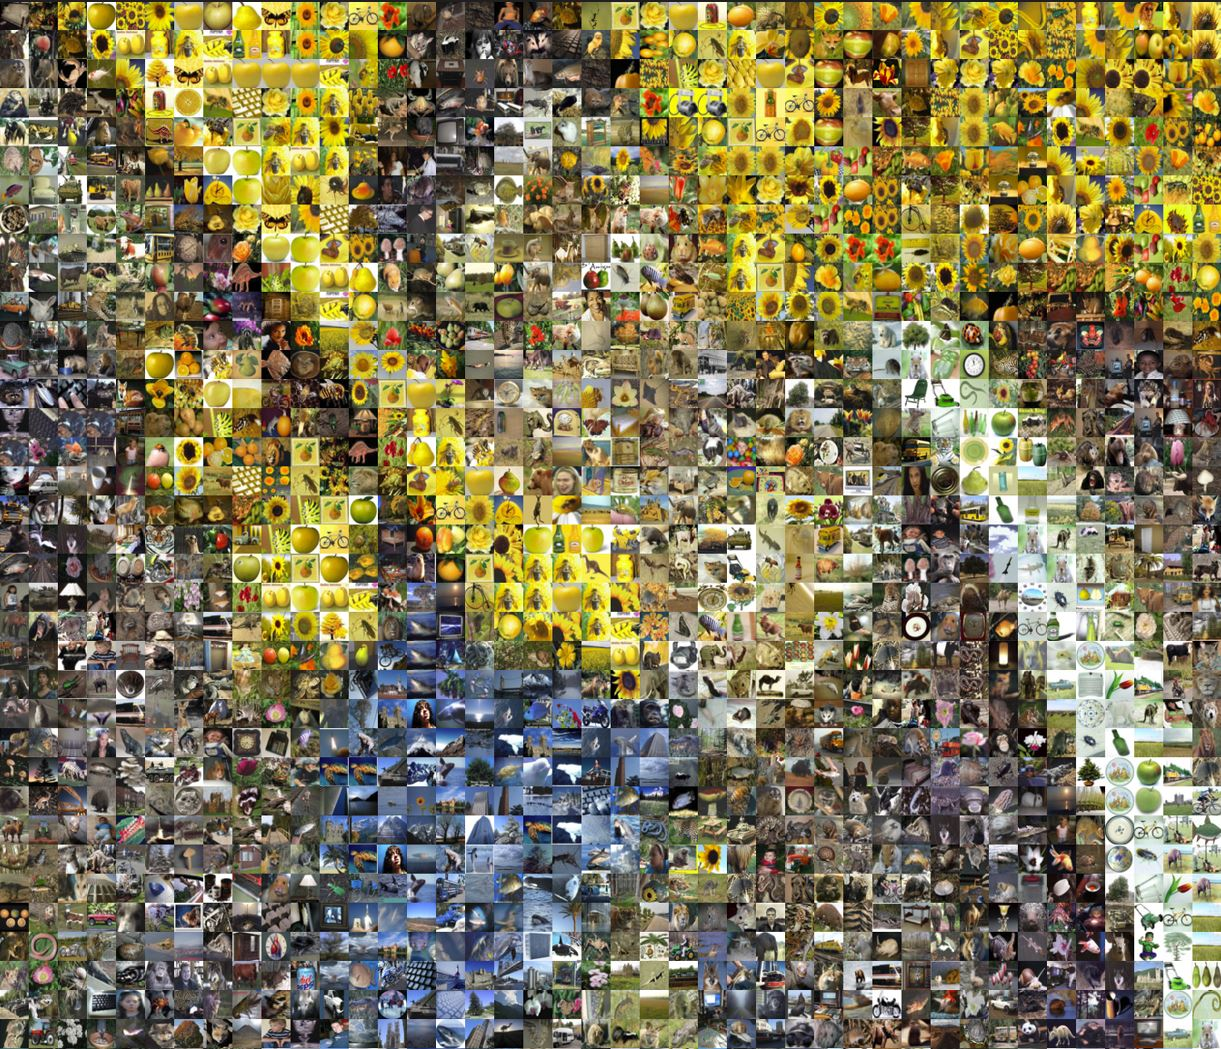

# Proposed algorithm
From a computational perspective, this is a hard task!
We will use an image with $P$ = ~200'000 pixels in an image. But it could easily be millions or even billions of pixels.

And for each pixel we will have to find a matching image. We will use cifar100 for the tiles, so that $T$ = 50'000 images. But it could easily be millions of images!

So a naive algorithm would have complexity $\Omega(PT)$ -- it's already terrible, but we haven't even considered that the tiles can be fairly large.

> You can try to brute-force it tell us how long it took.

**What to do, what to do!?**

First, by **input image** I mean the single large-ish image we want to turn into a mosaic. By a tile I mean each of the many small images which will be the tiles of the resulting mosaic.

In our example the input is 512x512 and the tiles are 32x32. Both are RGB images.

Now, we will do a couple of tricks:
- To find the matching tile, we will consider its mean color and compare it with the pixel which it's meant to replace. We just reduced the dimensionality of our data from $32*32*3$ to $3$. And it makes sense here!

> It's useful to think of these RGB vectors as *fingerprints* of the images. They contain only the crucial data (in this case mean color), but make the search process much easier.

- Since now our data is now 3-dimensional, we can just use kd-trees to look for nearest neighbours!

> You should remember from our notebook that kd-trees are super efficient for low dimensions, but their performance tends to degrade around d=100.

- So we will build a kd-tree on top of the mean-colors of tiles and query for each pixel in the input image.

> Note that a single query returns an index of the nearest mean-color -- but that's also the index of the tile we want!

- So now we have an index of a tile for each pixel in the input image.

- The last step is to convery these indices to the final image -- that's just (no so) basic numpy.

# Some things to watch out for:

> This could be some preemptive tips from a more experienced teammate, who solved similar problems

- Do *not* normalize the tiles, by dividing by 255. Keep the values as integers between 0 and 255. Note after loading cifar100 numpy represent each RGB intensity as a np.uint8 type. It only needs 1 byte (8 bits, one bit being 0 or 1) of memory. The default floating point value (np.float64) uses 8 bytes (64 bits). Normally it's not an issue, but we will generate very large images -- so if we use floats memory will likely blow up.

- The means can be stored as floats -- they don't take up too much space, and you get imprecisions otherwise. So they should be *floats* between 0 and 255.

- You can imshow a single color (RGB vector) by reshaping it into an array with shape (1,1,3).

- Remember you can create a larger figure, e.g. plt.figure(figsize=(20, 20))

- The hardest part is re-arranging the tiles in the correct order. It's **not** a simple reshape. The easy way of doing it, is to create a large empty np.array representing the ouput image -- and 'paste' each tile in the appropriate place in it. Remebmer about the fancy indexing like: output[32:64, 64:96] = some_tile.

- Don't use np.transpose and similar tricks -- a normal person would not be able to understand and validate it quickly!

- Overall, the main algorthm can be done in maybe 5 lines of code with no explicit loops. But not using loops may actually hurt the readability, I'd use them. Most of the computations happen inside the body of the innermost loop, so here loops won't hurt the performance!

- Don't read the image files using any other method, as it may result in a slightly different pixel values (even though it shouldn't).

- You can save the resulting nparray as an '.png' or '.jpg' image like this: Image.fromarray(result).save('out.png')

> The png version will be compressed losslessly and will look much better than jpg -- but the file may be huge! You can then download it and zoom in on your compute as I did in class. The jpg will be smaller but may look really bad.

> If you did everything perfectly, the computations should take maybe 5 seconds -- except for downloading the data and saving the huge image. So by default I wouldn't save it -- only if I want to download it. BTW. Colab's local files are accessible in the tab to the left (folder icon).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KDTree
from keras.datasets import cifar100 as tiles_dataset

# Used by some code I wrote for you
from PIL import Image
import urllib.request

# Data loading

In [2]:
def get_image(img_URL, w):
  '''Just downloads an image, resizes to size w x w and
    returns it as an np.array.
    Note that no normalization is performed.
  '''
  file_name = 'input_image_name_on_disk'
  urllib.request.urlretrieve(img_URL, file_name)
  im = Image.open(file_name)
  im = im.resize((w, w))
  return np.asarray(im)[..., :3] # removes a potential alpha channel

In [3]:
img_UF_URL = "http://people.clas.ufl.edu/hwagner/files/UF.png"
img_ravenna_URL = "http://people.clas.ufl.edu/hwagner/files/ravenna.jpg"


# Feel free to use another url for fun; it must point directly at an image file
mos = get_image(img_UF_URL, w=512)

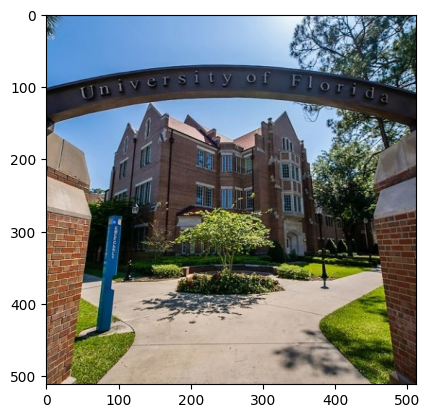

In [4]:
plt.imshow(mos)

In [5]:
# if it takes forever (minutes to hours), do mention it on discord!

!mkdir -p ~/.keras/datasets
!wget -O ~/.keras/datasets/cifar-100-python-target_archive \
    https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz

from tensorflow import keras

tiles = tiles_dataset.load_data()[0][0]

--2026-10-24 20:41:20--  https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz
Resolving data.brainchip.com (data.brainchip.com)... 146.59.209.152, 2001:41d0:301::31
Connecting to data.brainchip.com (data.brainchip.com)|146.59.209.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 169001437 (161M) [application/x-gzip]
Saving to: ‘/root/.keras/datasets/cifar-100-python-target_archive’

/root/.keras/datase 100%[===================>] 161.17M  11.0MB/s    in 18s     

2026-10-24 20:41:38 (9.19 MB/s) - ‘/root/.keras/datasets/cifar-100-python-target_archive’ saved [169001437/169001437]



# Task 1: the proof-of-concept (for computing the means)
First, compute the mean colors of all the tiles and construct a kd-tree.

> I'd actually have a look at some of the tiles, but that's just me.

Now generate 10 random colors and query the kd-tree for the nearest neighbours. For each of the 10 colors, imshow (in a horizontal row): the original color, the nearest mean color and the tile corresponding to the mean color.

> The results should make sense. Keep in mind that we're talking about the mean color. So something red on a which background will be pink on average!

If this looks good, we can move on to the actual mosaic implementation



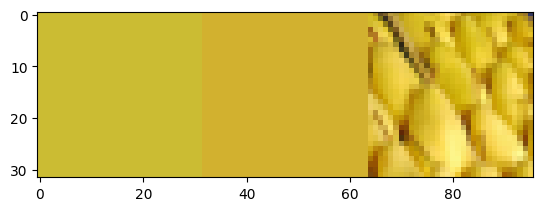

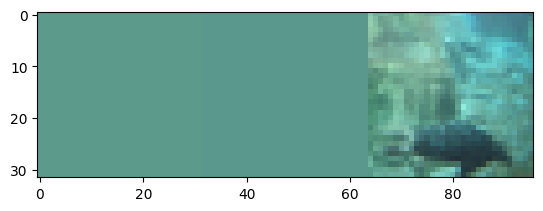

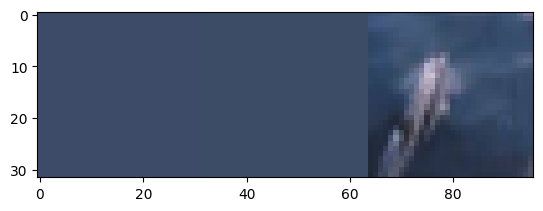

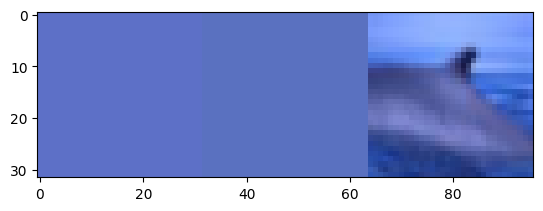

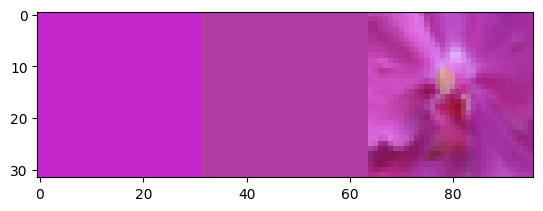

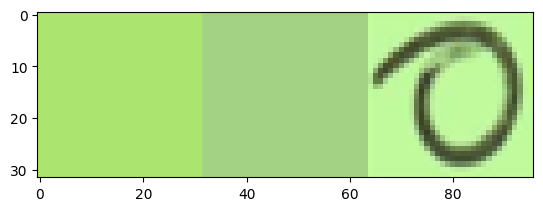

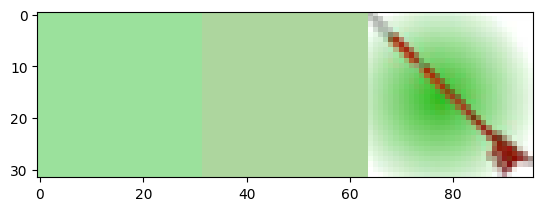

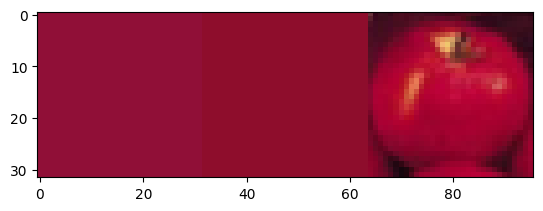

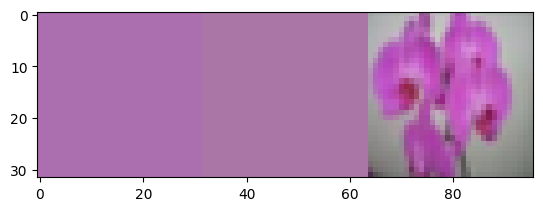

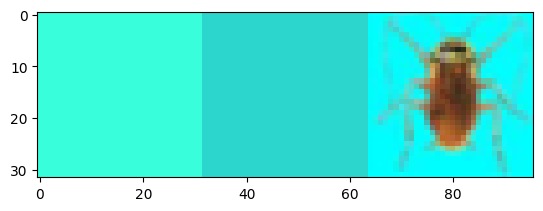

In [6]:
n, k_nearest = 10, 1

tile_means = tiles.mean(axis=(1, 2))

tree = KDTree(tile_means)

rand_colors = np.random.rand(n, 3) * 255
dist, inds = tree.query(rand_colors, k=k_nearest)

nearest_tiles = tiles[inds].reshape(-1, 32, 32, 3)

for i in range(n):
  rand_color = np.zeros((32, 32, 3), dtype=np.uint8)
  rand_color[:, :] = rand_colors[i]

  mean_color = np.zeros((32, 32, 3), dtype=np.uint8)
  mean_color[:, :] = tile_means[inds[i][0]]

  orig_tile = nearest_tiles[i]

  plt.imshow(np.concatenate([rand_color, mean_color, orig_tile], axis=1))
  plt.show()

# Task 2.0: draft of the mosaic implementation



If everything looks good in task 1, we are ready for the full algorithm. Good luck!

Please leave your initial implementation. This should be your original code. It can be broken, but it's good to see how much you will have learned by the end of this. Next time should be easier.

In [7]:
empty = np.zeros((512, 512, 3), dtype=np.uint8)

for i in range(512):
  for j in range(512):
    color = mos[i, j].reshape(-1, 3)
    dist, ind = tree.query(color, k=k_nearest)
    empty[i * 32 : (i + 1) * 32, j * 32 : (j + 1) * 32] = tiles[ind[0][0]]


ValueError: could not broadcast input array from shape (32,32,3) into shape (32,0,3)

# Task 2.1: The full-fledged mosaic implementation

Create a function make_mosaic which accepts all the necessary inputs. Make sure it's self contained.

Now take care of performance, code-quality, etc. See the next point about performance tuning using a profiler, that could help.

For full credit the computations (**without** displaying or saving to file) ought to take around 6-7 seconds! plt.imshowing the resulting mosaic will take forever.

> Try to follow the code-quality guidelines we used last time! If you use an automatic reformatter -- it's okay, but do show the before/after code.


> Reminder about variable names: i_am_a_python_pro vs iReallyLikeJava or IAlwaysNameMyFunctionsLikeInCSharp


In [8]:
def make_mosaic(mos, tree):
  '''Creates a large mosaic image by replacing each pixel of the input image
  with its nearest-matching CIFAR-100 tile based on mean color.

  args:
    mos (np.ndarray): the input image that will be turned into a mosaic with
      dimensions 512 x 512 x 3
    tree (KDTree): the pre-built KDTree containing the mean colors of the tiles

  returns:
    np.ndarray: The final mosaic with dimensions 512*32 x 512*32 x 3
  '''
  empty_canvas = np.zeros((512 * 32, 512 * 32, 3), dtype=np.uint8)



  pixels = mos.reshape(-1, 3)
  dist, inds = tree.query(pixels, k=k_nearest)

  grid = inds.reshape(512, 512)

  for i in range(512):
    for j in range(512):
      empty_canvas[i * 32 : (i + 1) * 32, j * 32 : (j + 1) * 32] = tiles[grid[i, j]]

  return empty_canvas

# Task 2.2: Profiling

If your function is too slow, it may not be obvious which specific lines or computations make it too slow. It's always a good idea to 'profile' your code, rather than guess what's slow.

## TODO: Even if your function is fast, do check which part takes what percentage of the time.

To do this we'll use a "line profiler", called lprun. It will tell us which **line** of our function takes up the most time. So e.g. kd-tree query. It will display the results in another window (by default showed on the right).

> Note that running code in this profiling mode makes it significantly slower. But the percentages (of time spant on each line) should be reliable.

You will call it below on your function, here is example output:

## Simple example profiler output

Timer unit: 1e-06 s

Total time: 5.200002 s

Line nr      Hits        Time   Per Hit   % Time   Line Contents
--
     1                                           def sum_squares(n):
     2         1         1.0      1.00      0.0       total = 0
     3  10000001   2000000.0      0.20     38.5       for i in range(n):
     4  10000000   3200000.0      0.32     61.5           total += i * i
     5         1         1.0      1.00      0.0       return total

> Python/colab comes with %prun but that'd measure all the internal functions -- but that's not so easy to interpret here.



In [ ]:
# we need to install lprun; unlile prun, it's not availably by default
%pip install -q line_profiler
%load_ext line_profiler

In [ ]:
# fix the function call below, keep the rest
%lprun -f make_mosaic final_image = make_mosaic(mos, tree)

# Task 3: Validation

Imshow the portion of the ouput image (numpy array) which corresponds to the top-left 8x8 tiles.

> Not talking about the 8x8 pixels!

Below I'm showing the correct image. If you look at your output and my output and the results are identical -- well done! In particular, all tiles should show the same thing.

> If you get something different here, you may have used some slight variation of the algorithm. Try to get exactly the same results, it's hard to grade otherwise.

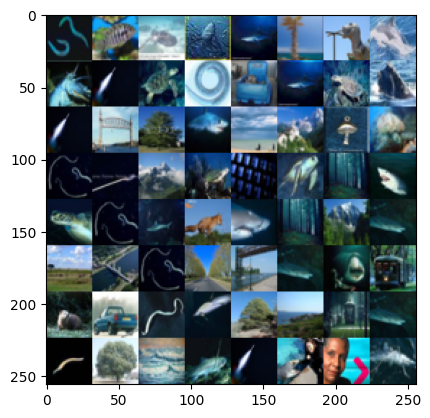

In [9]:
final_image = make_mosaic(mos, tree)
plt.imshow(final_image[: 8 * 32, : 8 * 32])


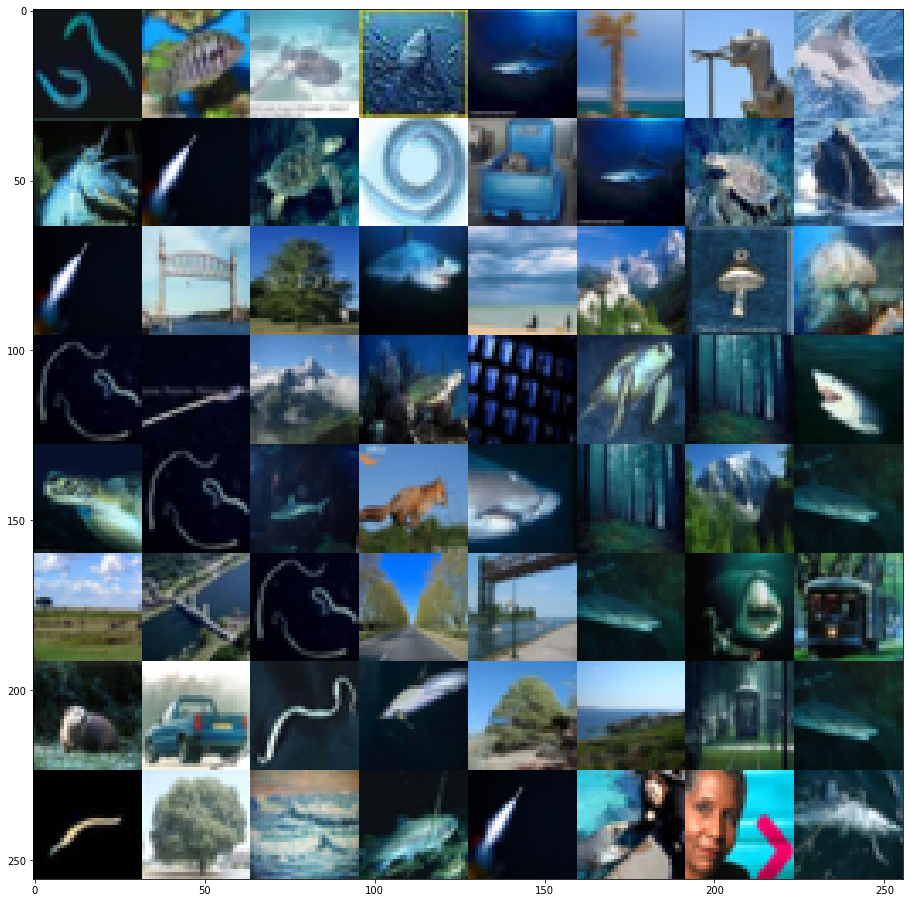

# Mini task 4:
Save the file to a .png and download on your disk. You can then open it in a photo viewer and zoom in and appreciate the result as we did in class. Select an interesting portion and copy-paste this image in the text cell below.


> You can also run it on another example image if you want.

In [10]:
# your code
Image.fromarray(final_image).save('mosaic_output.png')

KeyboardInterrupt: 

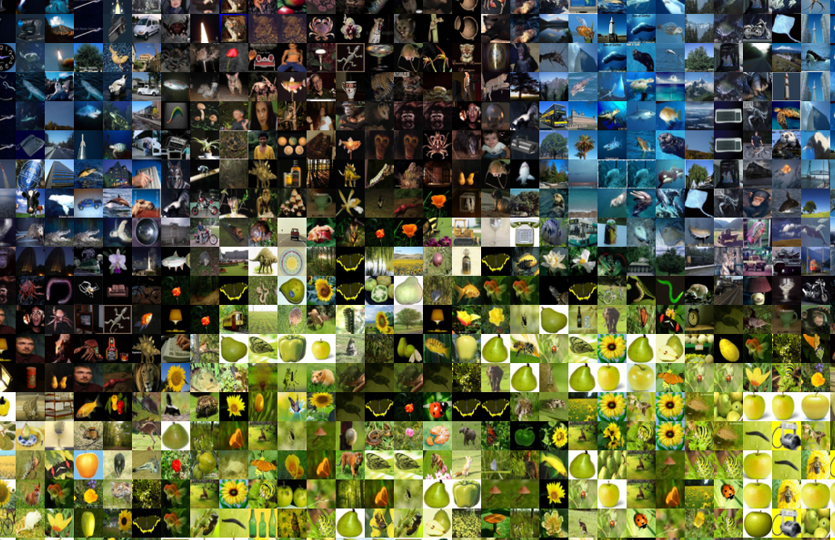

# Mini Task 5: One last thing...

Uncomment and run the code below after assigning
your final large mosaic to the variable X. You'll get a value which I'll ask you about in the form.

In [11]:
import hashlib

In [12]:
X = final_image # fix me
h = hashlib.sha256(X.tobytes(order="C")).hexdigest()
print(h) # let me know on discord if there are any issues with the above

5721b89bc08e72a31ecfc82c74c37c637321c46e7876770efbccdd08dc9ab9d9


# Bonus [some extra credit, could be a lot if you do something interesting]:
Try to improve this method. If you managed to do someting interesting -- show how the versions compare. Maybe plot the same portions of the mosaic side by side?

> This is a good way to get back points you may have lost in previous assignments!

- One shortcoming is that we will often get patches of similar images -- can we do something about this in an elegant way? Can you implement this version and compare the results?

- Maybe just taking the mean color is not what we really want? I mean the idea is that the derived color kind of corresponds to how we percieve a tile from afar. Can you propose and test and alternative approach?

- Maybe taking the means loses too much information. Can you try a more fine-grained fingerprint?

- Maybe using the Euclidean distance is not the best way to compare colors? Can you try out some variation?

> An extreme version of this problem is an 'infinite zoom' version done in real-time. So as you keep zooming in the pixels of the tiles would be revealed to be images -- and you could zoom in like that forever. I've never impleented this, but I suspect it's actually feasibly on moderns GPU (similar data-structures are used for raytracing). Maybe some of you have  thoughts on this.